In [32]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics 

### Importing the Required Libraries

Before starting the analysis, I imported the libraries needed for data manipulation, visualization, and machine learning. Pandas and NumPy provide the tools for working with structured data and numerical operations, while Matplotlib and Seaborn help explore patterns and relationships between variables. I also imported `train_test_split` to divide the dataset into training and testing subsets, `GaussianNB` to build the classification model, and the metrics module to evaluate its predictions.

Organizing these imports at the beginning keeps the workflow clear and makes the required tools available throughout the project.


In [2]:
df=pd.read_csv('E:\\Learning\\Machine_Learning\\Data-EDA\\Poroje\\ML\\Naive Bayes\\diabetes1.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


### Loading the Diabetes Dataset

I loaded the diabetes dataset into a Pandas DataFrame to establish the starting point of the project. The dataset contains patient-related measurements and an `Outcome` column that indicates the target class. This target allows the task to be approached as a supervised classification problem: the model learns patterns from the recorded features and uses them to predict the outcome for new observations.

Displaying the dataset at this stage provides an initial view of its structure, column names, and recorded values before selecting features or building a model.


In [3]:
table = pd.DataFrame(df.drop('Pregnancies' , axis=1))
table

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
2,183,64,0,0,23.3,0.672,32,1
3,89,66,23,94,28.1,0.167,21,0
4,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...
763,101,76,48,180,32.9,0.171,63,0
764,122,70,27,0,36.8,0.340,27,0
765,121,72,23,112,26.2,0.245,30,0
766,126,60,0,0,30.1,0.349,47,1


### Creating the Working Dataset

I created a working DataFrame while excluding the `Pregnancies` column. This defines the set of variables that will be explored in the following steps and used in the subsequent modeling workflow. By separating this working table from the original DataFrame, I can perform the analysis on the selected features while preserving the original dataset as a reference.

The remaining variables describe different aspects of the patients' medical measurements and demographic information, while `Outcome` remains available as the target for classification.


In [4]:
table.describe()

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Exploring the Numerical Summary

I used the `describe()` method to obtain a statistical summary of the selected variables. The output includes the number of observations, mean, standard deviation, minimum, quartiles, and maximum for each numerical column.

This step helps establish the scale and distribution of the measurements before modeling. It also provides an initial way to identify unusual values and understand how much the measurements vary across observations. These summaries support the exploratory analysis by turning the raw dataset into a more interpretable numerical overview.


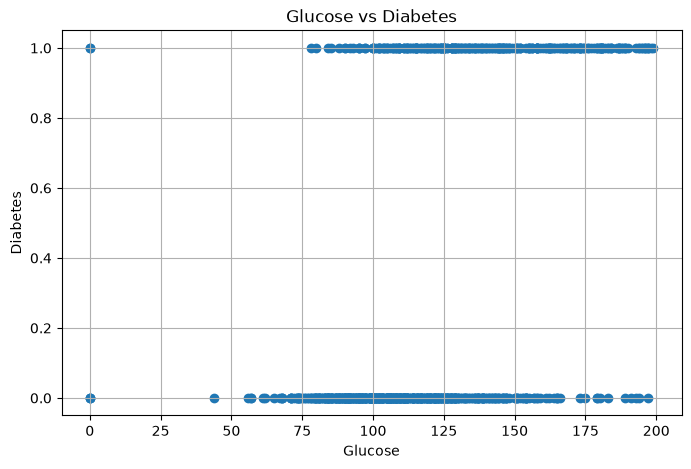

In [8]:
plt.figure(figsize=(8,5))
plt.scatter(table['Glucose'] , table['Outcome'])
plt.xlabel('Glucose')
plt.ylabel('Diabetes')
plt.title('Glucose vs Diabetes')
plt.grid()

### Exploring Glucose in Relation to the Outcome

I created a scatter plot to examine how glucose measurements are distributed across the two outcome classes. Since `Outcome` represents a binary target, the points appear in two horizontal bands, making it possible to compare the glucose values associated with each class.

This visualization helps investigate whether glucose levels show a visible relationship with the target. It also provides an intuitive introduction to the classification task by showing how a numerical feature may help distinguish between patients in different outcome groups.


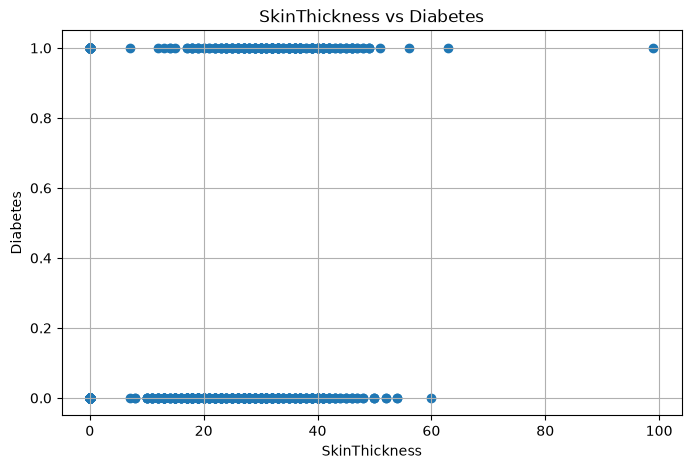

In [9]:
plt.figure(figsize=(8,5))
plt.scatter(table['SkinThickness'] , table['Outcome'])
plt.xlabel('SkinThickness')
plt.ylabel('Diabetes')
plt.title('SkinThickness vs Diabetes')
plt.grid()

### Exploring Skin Thickness in Relation to the Outcome

I used a scatter plot to examine the relationship between skin thickness and the diabetes outcome. Visualizing the feature against the target helps reveal the range of recorded measurements in each class and whether the two groups appear to have different distributions.

This step is useful because a feature may contribute information to classification even when the classes overlap. The plot therefore supports an initial assessment of the potential usefulness of skin thickness without assuming that it can independently determine the outcome.


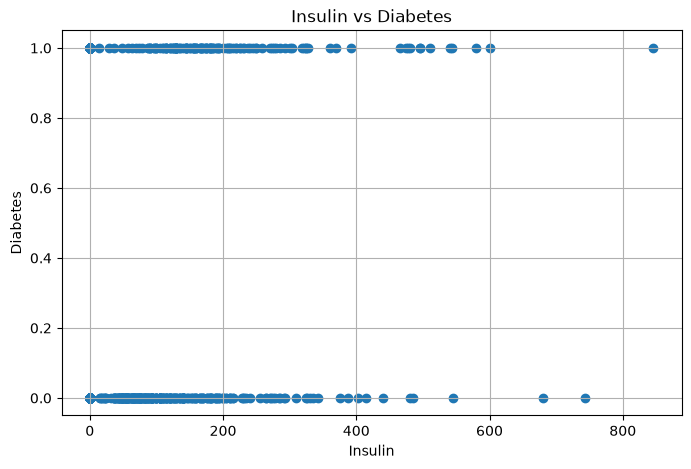

In [10]:
plt.figure(figsize=(8,5))
plt.scatter(table['Insulin'] , table['Outcome'])
plt.xlabel('Insulin')
plt.ylabel('Diabetes')
plt.title('Insulin vs Diabetes')
plt.grid()

### Exploring Insulin in Relation to the Outcome

I plotted insulin measurements against the diabetes outcome to investigate how this feature varies between the two target classes. The visualization makes the spread of the recorded values easier to observe and helps identify whether the measurements show patterns that may be relevant to classification.

Examining individual features before model training provides context for the later predictions. It helps connect the machine learning stage to the underlying data rather than treating the model as a black box.


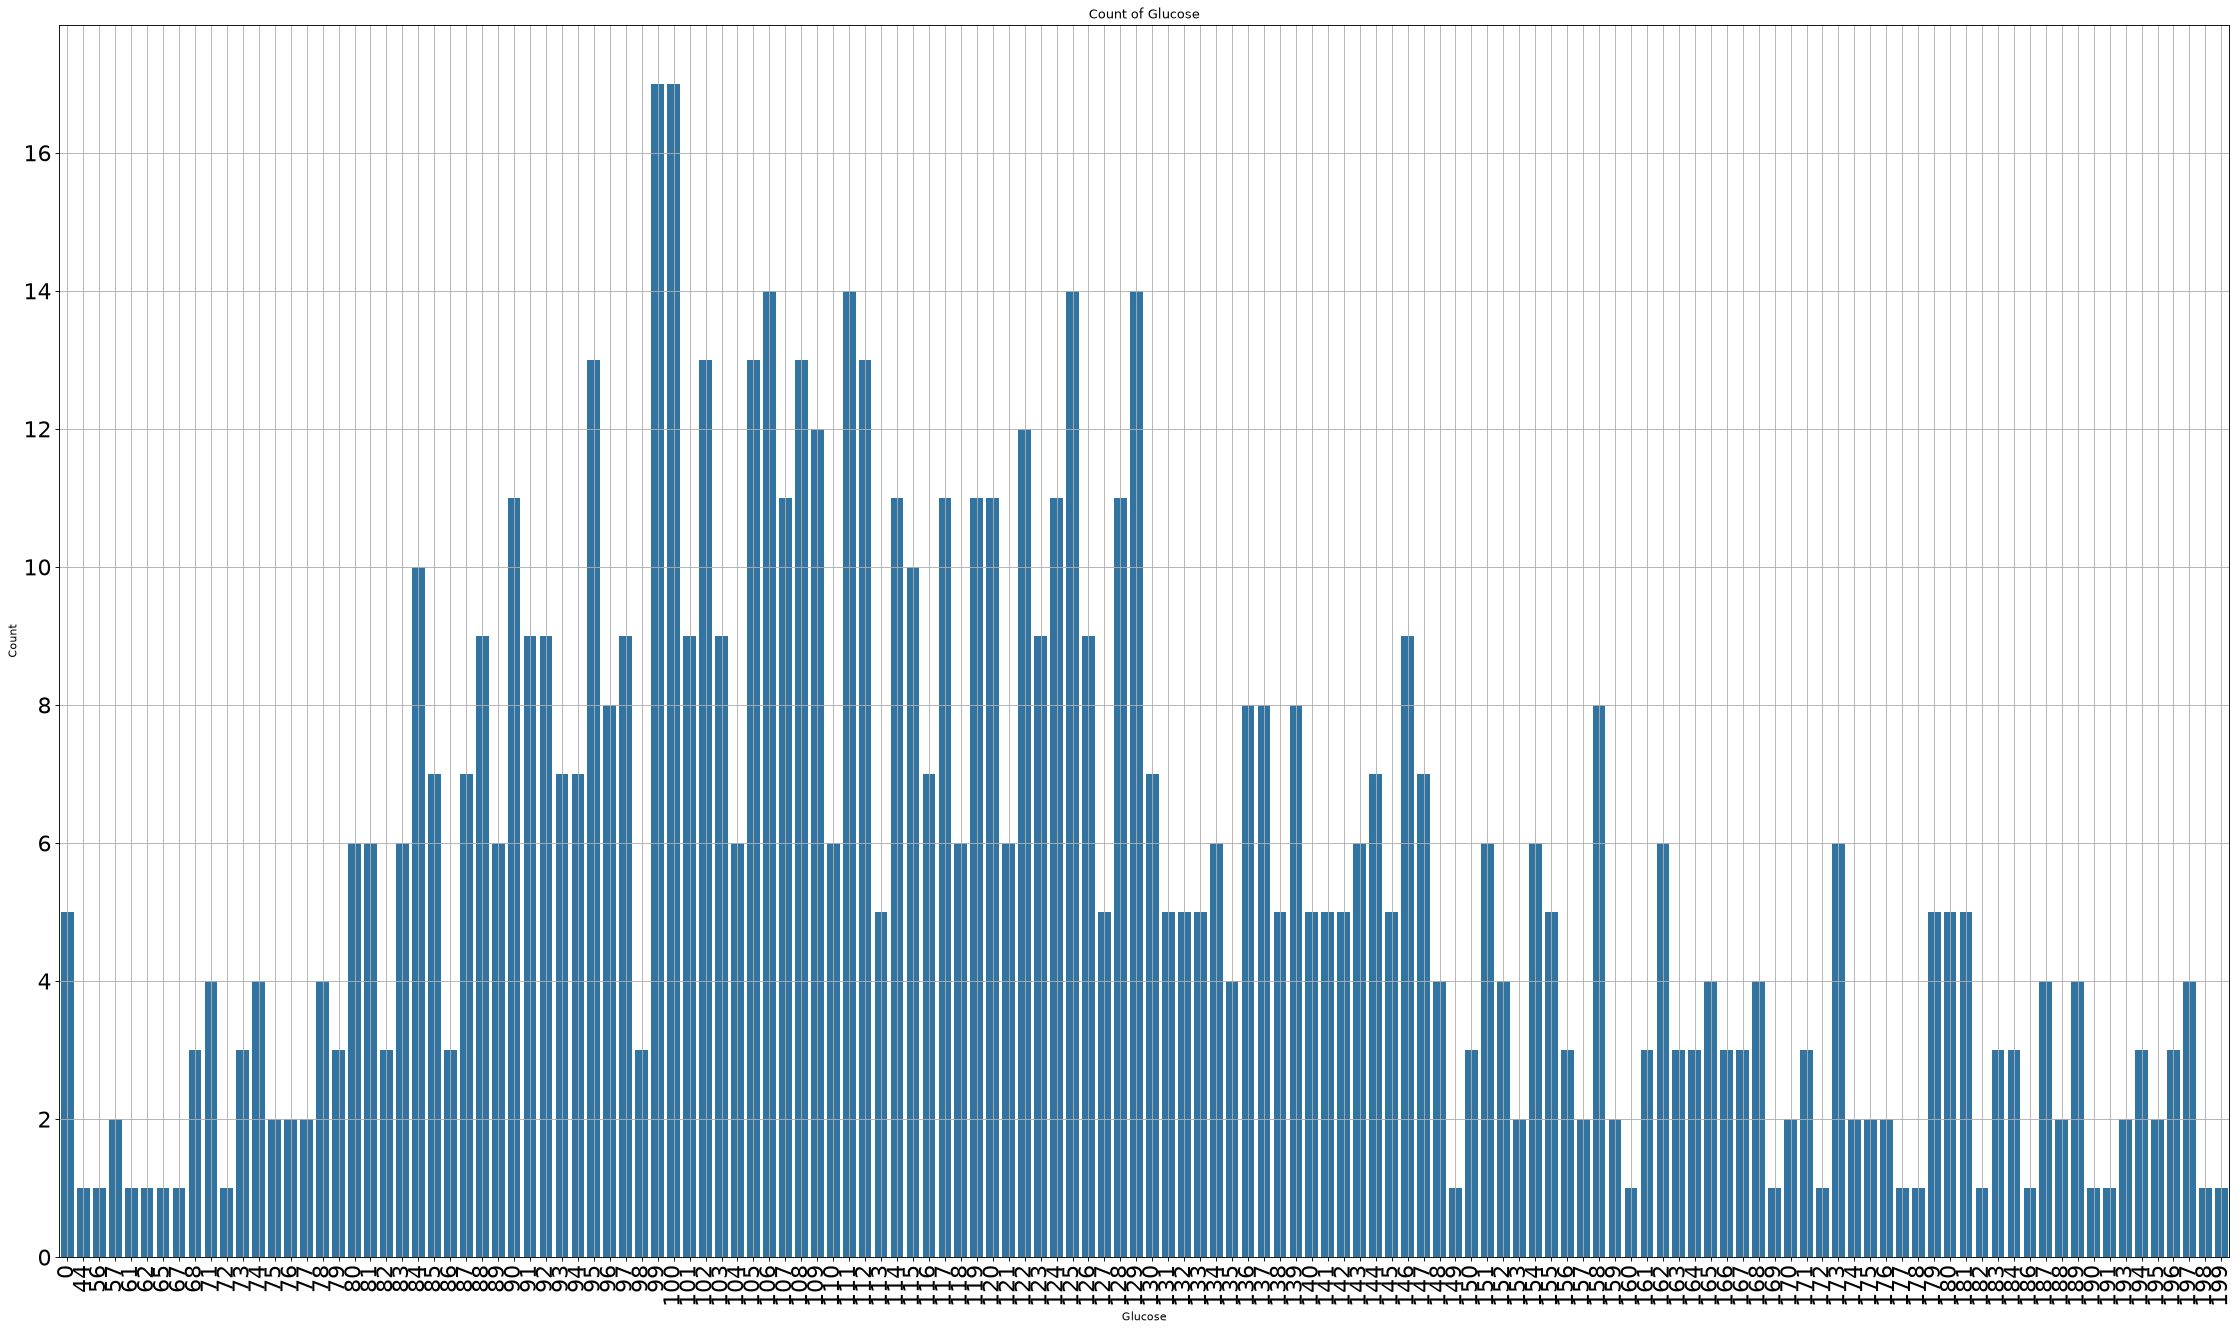

In [11]:
plt.figure(figsize=(35,20) , dpi=80)
ax = sns.countplot(x='Glucose' , data=table)
plt.xticks(rotation = 90 , fontsize = 20)
plt.yticks(fontsize = 20)
plt.xlabel('Glucose')
plt.ylabel('Count')
plt.title('Count of Glucose')
plt.grid()

### Examining the Frequency of Glucose Values

I used a count plot to examine how frequently different glucose values occur in the dataset. This visualization focuses on the frequency of individual recorded values rather than directly comparing the outcome classes.

Understanding the frequency distribution helps identify which values are common and which occur less often. This is useful during exploratory data analysis because the concentration of observations can influence how representative different regions of the feature space are when the model learns from the data.


Text(0.5, 1.0, 'Distribution of Glucose')

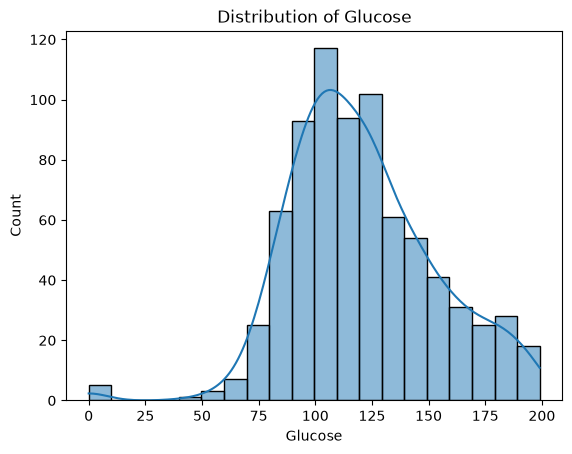

In [13]:
sns.histplot(data = table , x='Glucose' ,bins=20 , kde=True)
plt.title('Distribution of Glucose')

### Visualizing the Distribution of Glucose

I used a histogram with a kernel density estimate to examine the overall distribution of glucose measurements. The histogram groups values into intervals, while the density curve provides a smoother view of the distribution's general shape.

This visualization complements the count plot by making the broader distribution easier to interpret. It helps reveal where observations are concentrated and whether the distribution appears symmetric or skewed, providing useful context for understanding the numerical features used in the classification model.


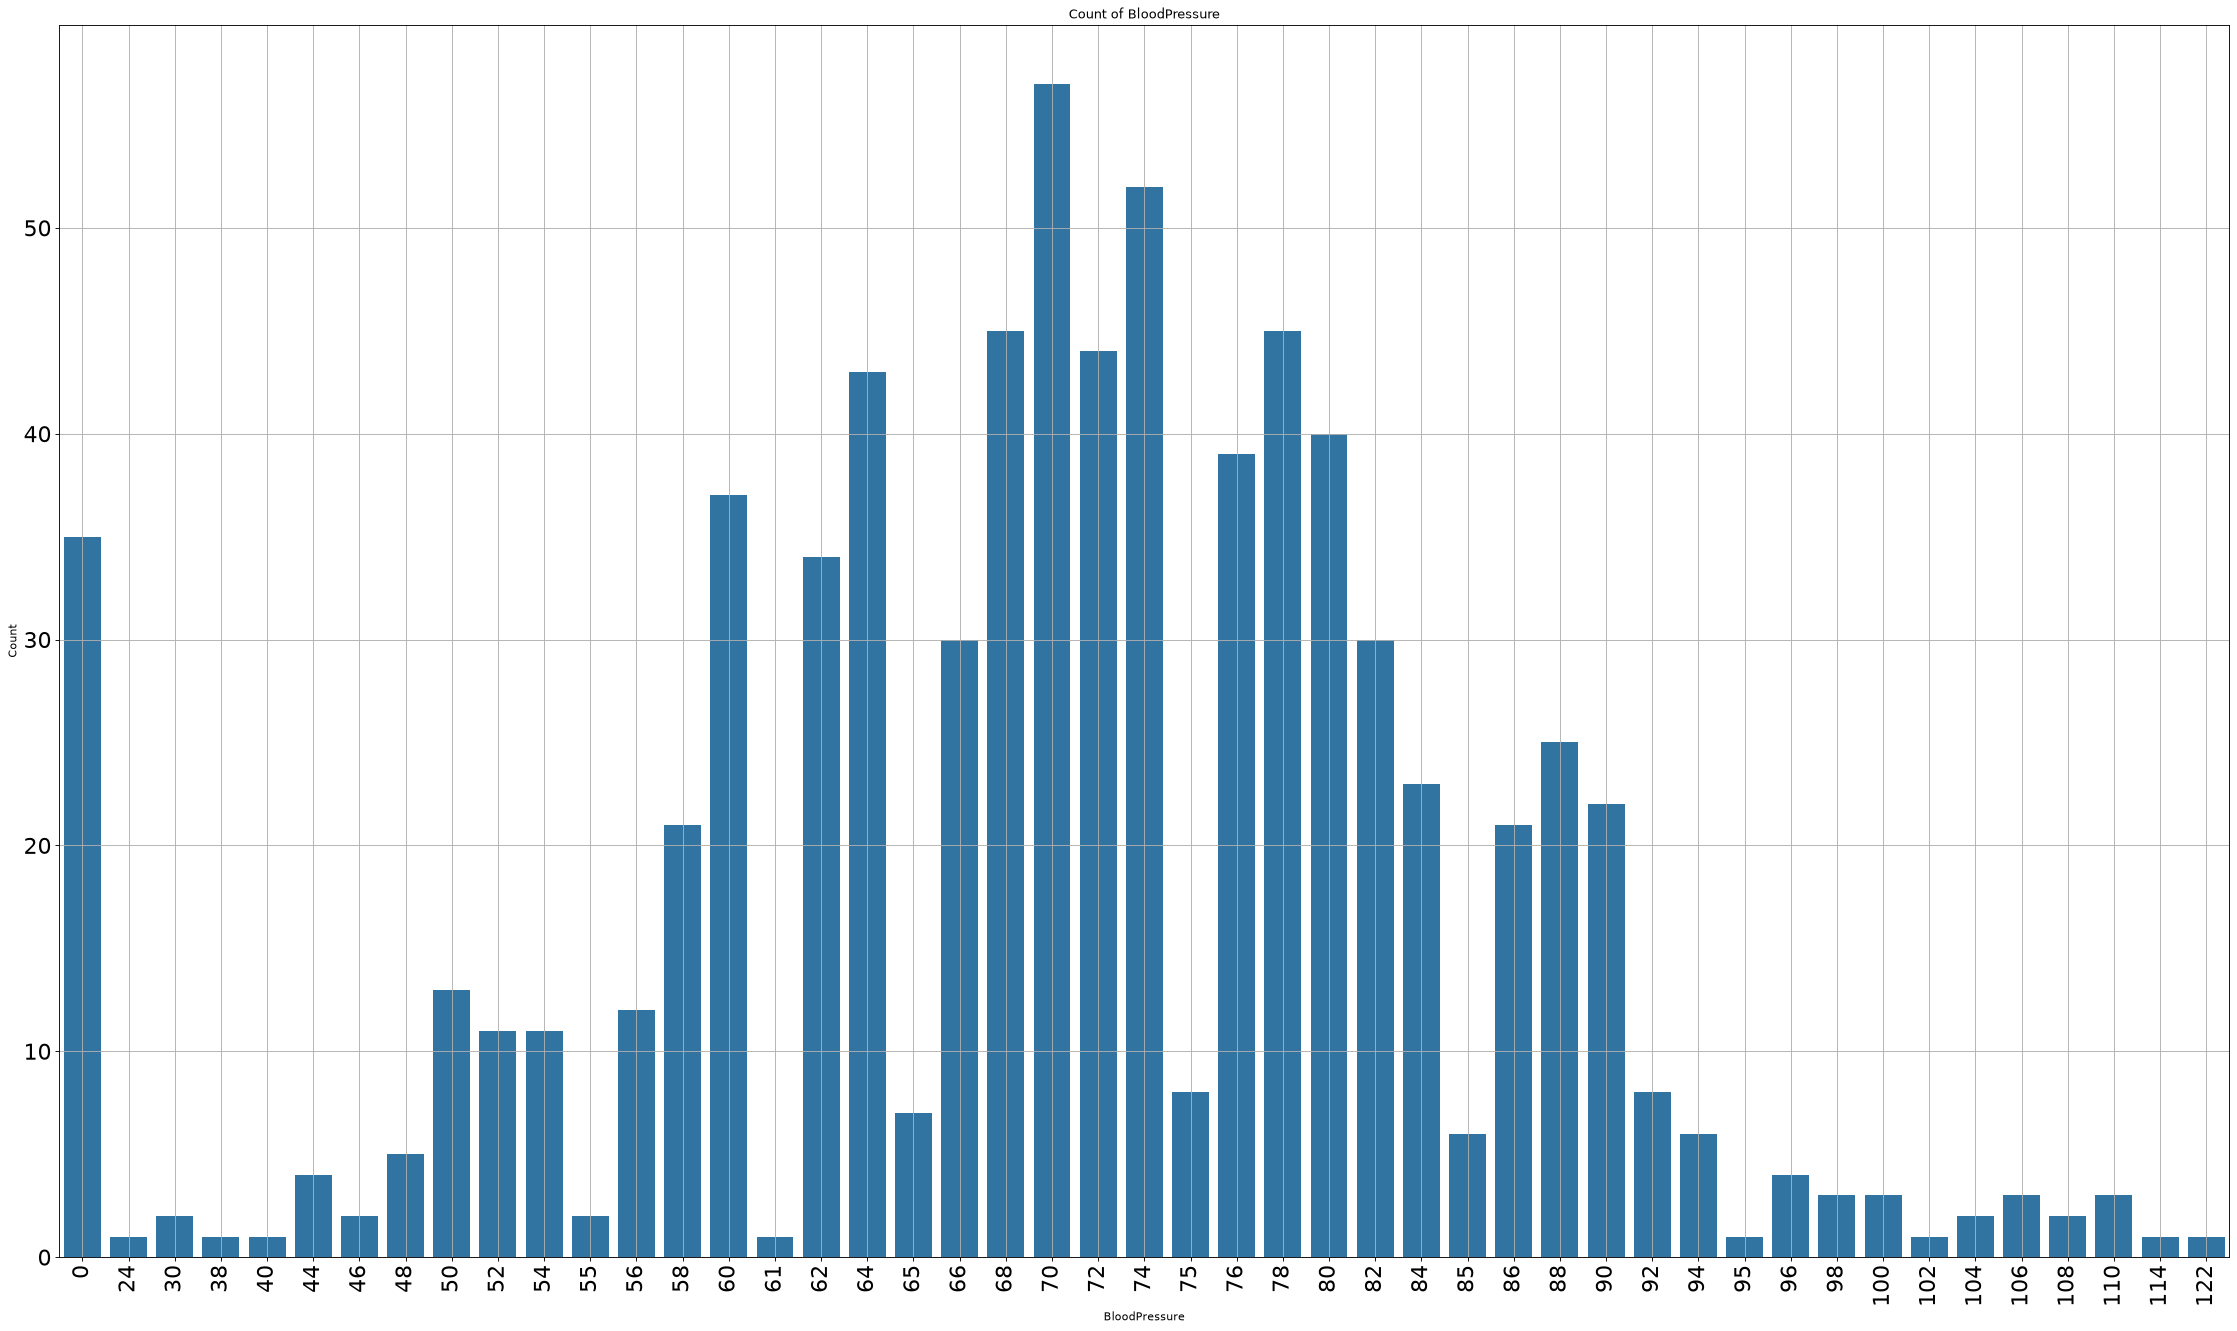

In [14]:
plt.figure(figsize=(35,20) , dpi=80)
ax = sns.countplot(x='BloodPressure' , data=table)
plt.xticks(rotation = 90 , fontsize = 20)
plt.yticks(fontsize = 20)
plt.xlabel('BloodPressure')
plt.ylabel('Count')
plt.title('Count of BloodPressure')
plt.grid()

### Examining Blood Pressure Frequencies

I created a count plot to explore the frequency of recorded blood pressure values. This allows me to see how observations are distributed across the values present in the dataset and whether certain values occur much more frequently than others.

Examining this feature separately helps build a clearer understanding of the data before combining it with other medical measurements. The resulting view contributes to the exploratory stage by showing the frequency structure of one of the numerical features used in the project.


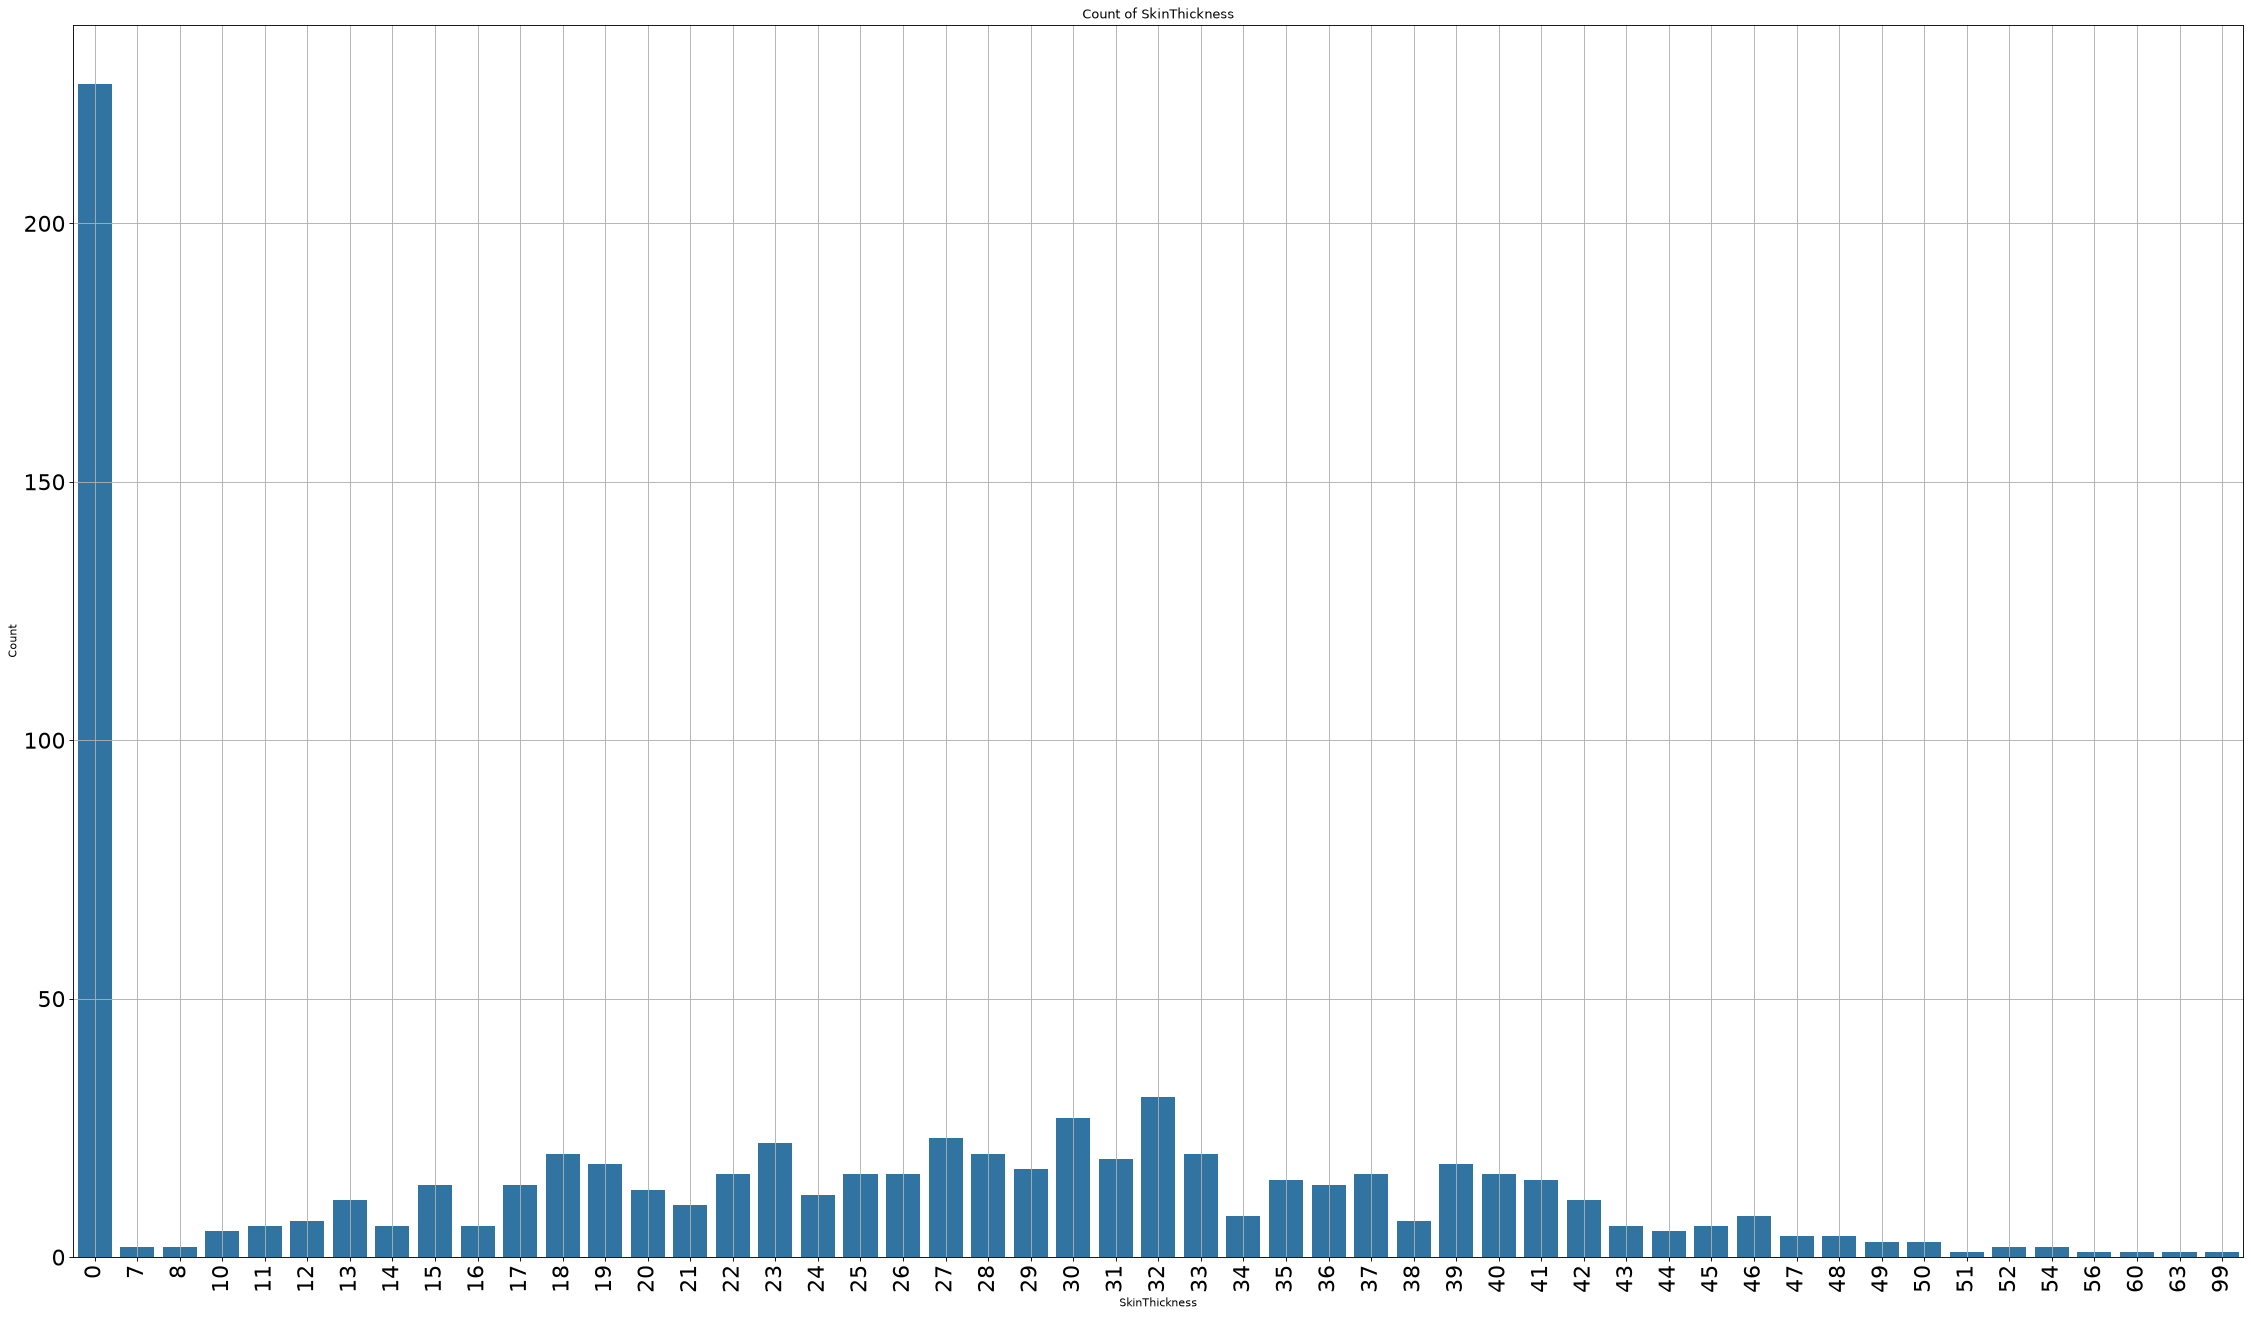

In [15]:
plt.figure(figsize=(35,20) , dpi=80)
ax = sns.countplot(x='SkinThickness' , data=table)
plt.xticks(rotation = 90 , fontsize = 20)
plt.yticks(fontsize = 20)
plt.xlabel('SkinThickness')
plt.ylabel('Count')
plt.title('Count of SkinThickness')
plt.grid()

### Examining Skin Thickness Frequencies

I used a count plot to inspect the frequency of skin thickness values. This is particularly useful for understanding how often individual measurements appear and whether the dataset contains a concentration of observations at specific values.

The frequency pattern provides context for the later filtering step, where I create a subset based on the recorded skin thickness values. Reviewing the distribution before applying that selection helps make the data preparation process easier to understand.


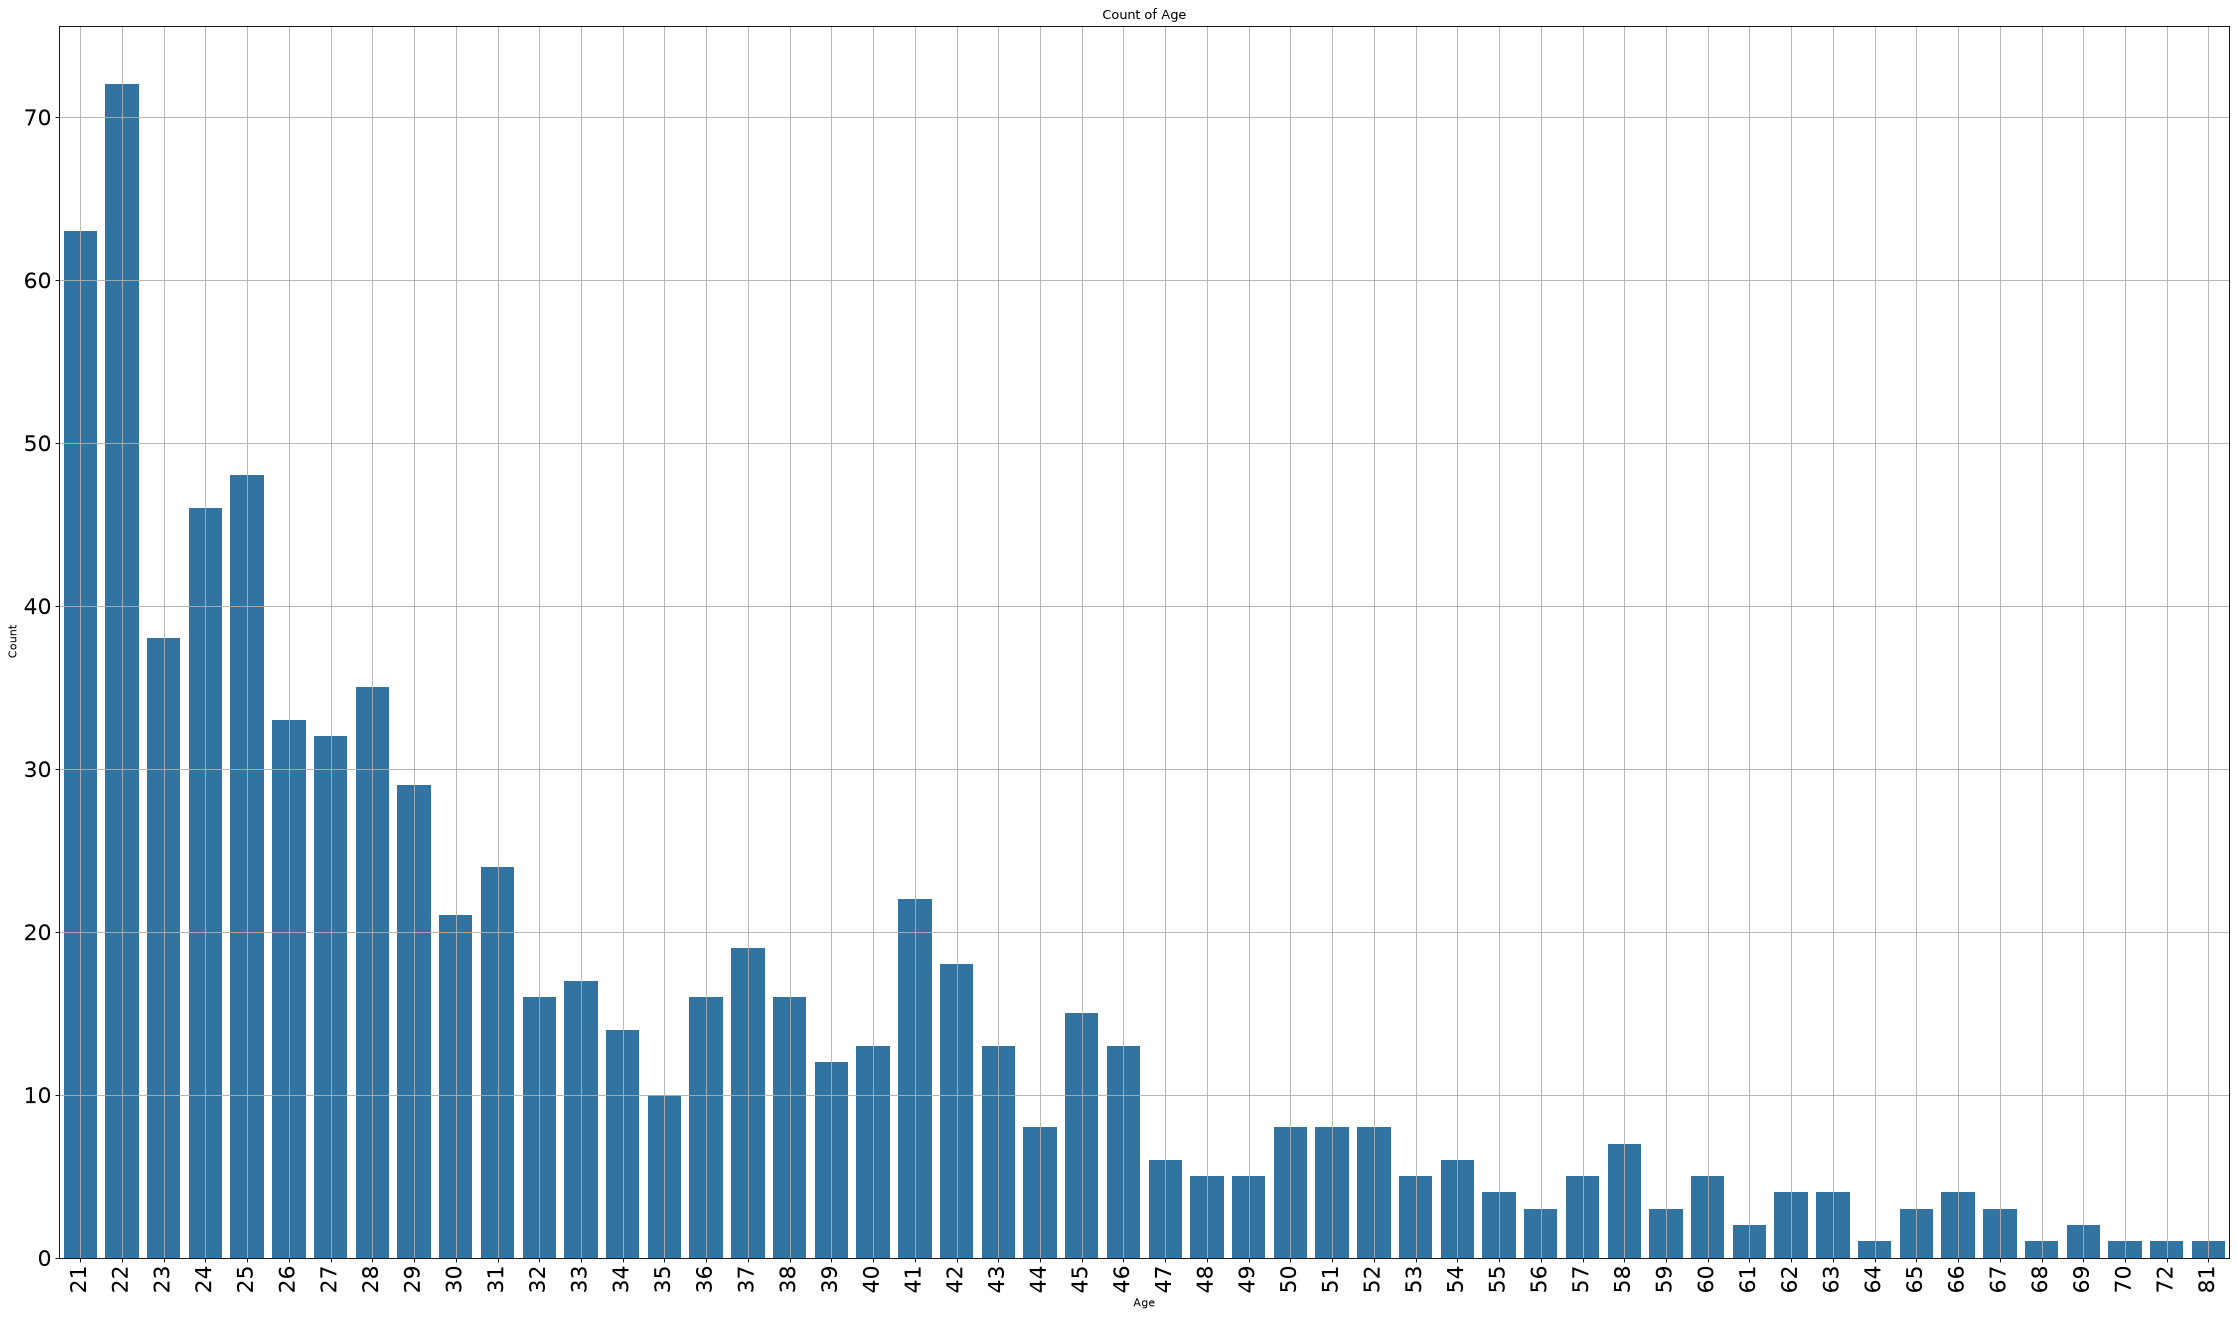

In [16]:
plt.figure(figsize=(35,20) , dpi=80)
ax = sns.countplot(x='Age' , data=table)
plt.xticks(rotation = 90 , fontsize = 20)
plt.yticks(fontsize = 20)
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Count of Age')
plt.grid()

### Exploring the Age Distribution

I used a count plot to examine the frequency of ages represented in the dataset. Age is an important demographic feature to explore because the distribution shows which age groups are more strongly represented in the available observations.

Understanding the sample's age distribution helps place the later model results in context. A model trained on a dataset with a particular age composition learns from the patterns represented in that sample, so knowing how the observations are distributed is part of interpreting the dataset responsibly.


In [20]:
table1 = table[table['SkinThickness'] > 0]
table1 = table1[table1['SkinThickness'] < 90]

### Creating a Filtered Dataset

I created a new DataFrame, `table1`, by selecting observations with skin thickness values greater than zero and less than 90. This selection defines the range of values retained for the subsequent analysis.

The lower boundary excludes zero values, while the upper boundary limits the selected observations to values below the specified threshold. Creating a separate DataFrame allows the later analysis and model training to use this selected subset while keeping the earlier working table available for reference.


In [21]:
table1

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
3,89,66,23,94,28.1,0.167,21,0
4,137,40,35,168,43.1,2.288,33,1
6,78,50,32,88,31.0,0.248,26,1
...,...,...,...,...,...,...,...,...
761,170,74,31,0,44.0,0.403,43,1
763,101,76,48,180,32.9,0.171,63,0
764,122,70,27,0,36.8,0.340,27,0
765,121,72,23,112,26.2,0.245,30,0


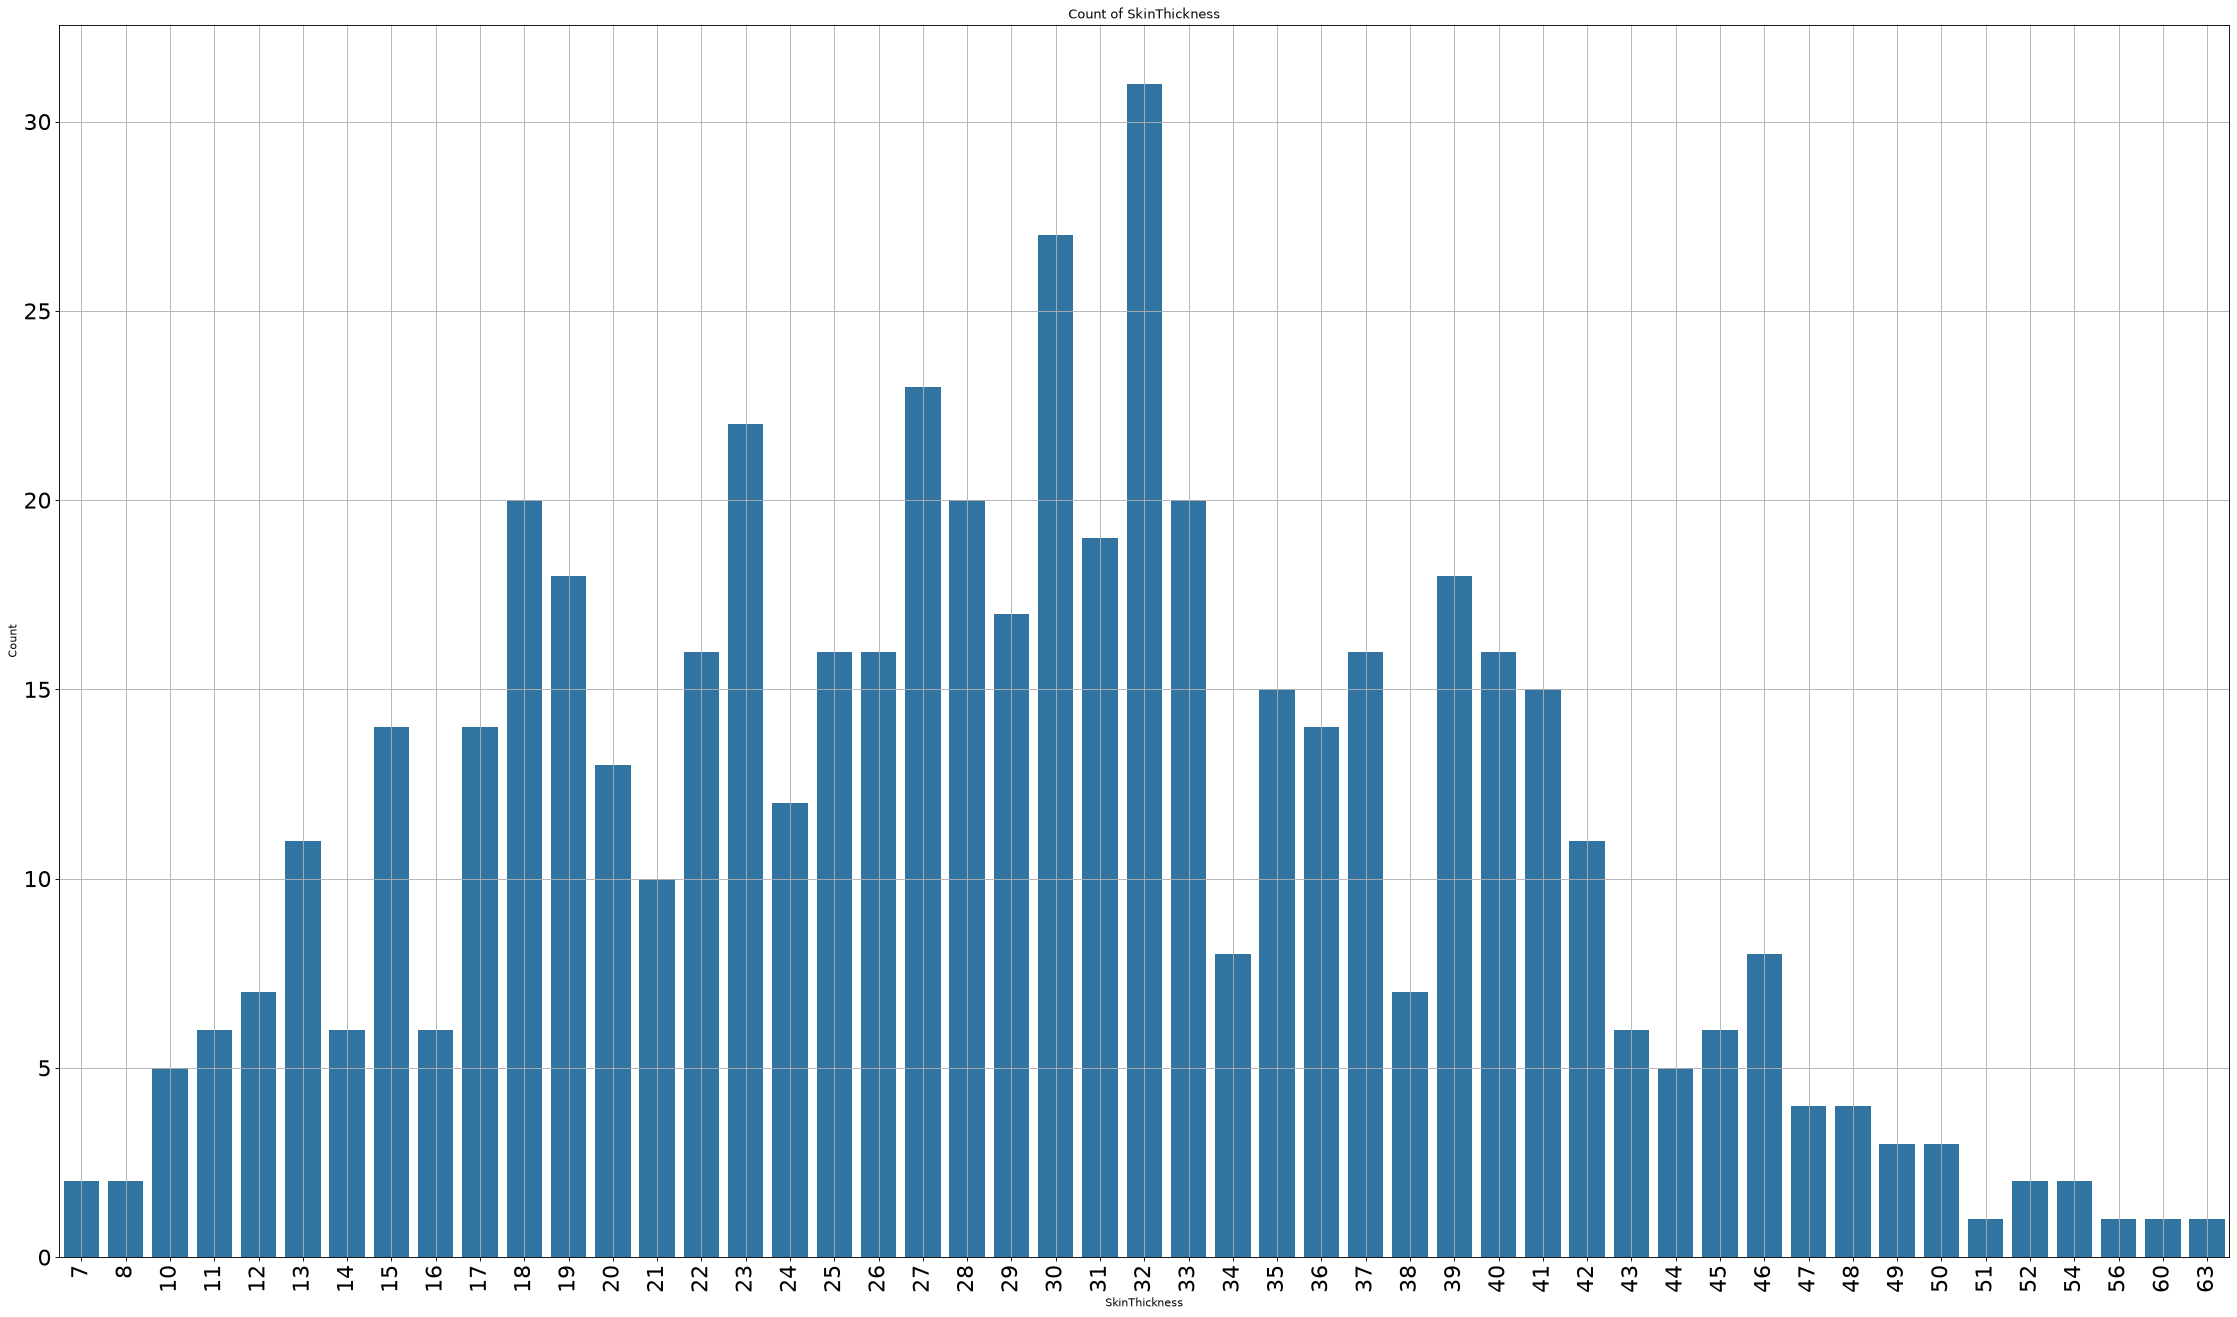

In [23]:
plt.figure(figsize=(35,20) , dpi=80)
ax = sns.countplot(x='SkinThickness' , data=table1)
plt.xticks(rotation = 90 , fontsize = 20)
plt.yticks(fontsize = 20)
plt.xlabel('SkinThickness')
plt.ylabel('Count')
plt.title('Count of SkinThickness')
plt.grid()

### Examining Skin Thickness After Filtering

I created a new count plot using the filtered dataset to examine the frequency of skin thickness values after the selection was applied. Comparing this visualization with the earlier count plot helps illustrate how the selected range changes the distribution being analyzed.

This step documents the filtered dataset's characteristics before it is used in the modeling workflow. It also helps show how a data selection decision affects the observations available for further analysis.


Text(0.5, 1.0, 'Distribution of SkinThickness')

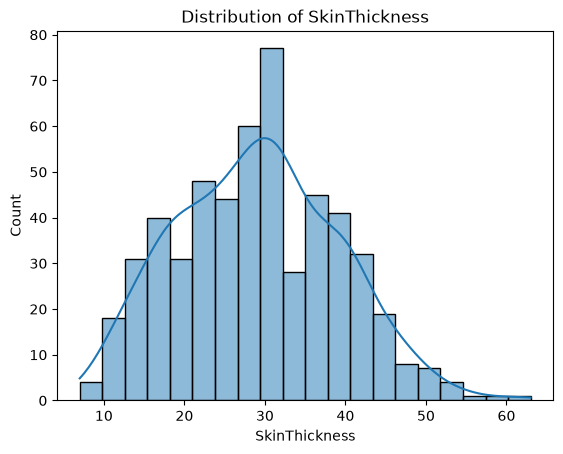

In [24]:
sns.histplot(data = table1 , x='SkinThickness' ,bins=20 , kde=True)
plt.title('Distribution of SkinThickness')

### Visualizing the Filtered Distribution

I used a histogram and kernel density estimate to examine the distribution of skin thickness in the filtered dataset. The histogram shows the frequency of values across intervals, while the density curve summarizes the distribution's overall shape.

This visualization complements the filtered count plot by providing a broader view of how the retained measurements are distributed. Together, these plots document the feature's behavior after applying the chosen selection criteria.


In [26]:
table1 = table1.dropna(how='any')
table1.reset_index(drop=True , inplace=True)

### Preparing the Data for Modeling

I used `dropna()` to remove rows containing missing values and then reset the DataFrame index. This prepares the selected dataset for the next stage, where the features and target are separated and passed to the machine learning workflow.

Resetting the index creates a consecutive index for the remaining rows, making the resulting DataFrame easier to inspect and work with. The cleaned table now serves as the input for the feature-selection and train-test split steps that follow.


In [28]:
x = pd.DataFrame(table1 , columns=['Glucose' , 'BloodPressure' , 'SkinThickness' , 'Insulin' , 'BMI' , 'DiabetesPedigreeFunction' , 'Age'])
y = table1.Outcome.values.reshape(-1,1)
x

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,148,72,35,0,33.6,0.627,50
1,85,66,29,0,26.6,0.351,31
2,89,66,23,94,28.1,0.167,21
3,137,40,35,168,43.1,2.288,33
4,78,50,32,88,31.0,0.248,26
...,...,...,...,...,...,...,...
535,170,74,31,0,44.0,0.403,43
536,101,76,48,180,32.9,0.171,63
537,122,70,27,0,36.8,0.340,27
538,121,72,23,112,26.2,0.245,30


### Separating the Input Features and Target

I defined `x` as the DataFrame containing the selected patient measurements and demographic features, while `y` stores the `Outcome` values as the target array. This separation establishes the inputs and expected outputs for supervised learning.

The model will use the columns in `x` to learn patterns associated with the classes represented in `y`. Keeping the features and target separate makes the machine learning workflow explicit and allows the data to be divided into training and testing subsets in the next step.


In [29]:
x_train ,x_test ,y_train ,y_test = train_test_split(x,y,test_size=0.35,random_state=0)


### Splitting the Dataset into Training and Testing Sets

I used `train_test_split()` to divide the selected data into training and testing subsets, reserving 35% of the observations for testing. The training subset is used to estimate the model's parameters, while the testing subset provides observations that were not used during fitting.

I set `random_state=0` to make the split reproducible, so running the same code again produces the same partition. This separation provides a basis for assessing how well the trained classifier predicts outcomes for observations outside the training subset.


In [30]:
clf = GaussianNB()
clf.fit(x_train,y_train.ravel())
y_pred = clf.predict(x_test)

### Building the Gaussian Naive Bayes Classifier

I selected `GaussianNB` as the classification algorithm for this experiment. Gaussian Naive Bayes is a probabilistic supervised learning method based on Bayes' theorem. It estimates the probability of each target class given the observed feature values and assigns a class according to the resulting probabilities.

The Gaussian variant assumes that each numerical feature follows a Gaussian, or normal, distribution within each class. It also uses the Naive Bayes assumption that the features are conditionally independent given the target class. These assumptions allow the model to estimate class-specific feature distributions and combine their contributions efficiently.

I trained the classifier using `x_train` and `y_train`. The call to `ravel()` converts the target array into a one-dimensional structure expected by the classifier. After fitting, I used `predict()` on `x_test` to generate predictions for the held-out observations. These predictions are stored in `y_pred` for evaluation in the following cells.

I chose this model as a useful baseline because it is computationally efficient and provides a clear probabilistic approach to a binary classification problem.


In [33]:
print('Accuracy :' , metrics.accuracy_score(y_test,y_pred))

Accuracy : 0.7671957671957672


### Measuring Classification Accuracy

I calculated the model's accuracy by comparing `y_pred` with `y_test`. Accuracy measures the proportion of test observations for which the predicted class matches the actual class.

This metric provides an initial summary of the classifier's predictive performance on the held-out test set. It is useful as a starting point, but it does not show how performance differs between patients classified as diabetic and non-diabetic. For that reason, I also examine class-level metrics and the confusion matrix in the following steps.


In [34]:
from sklearn.metrics import classification_report, confusion_matrix
clf.classes_

array([0, 1])

### Checking the Classes Recognized by the Model

I inspected the `classes_` attribute to identify the class labels learned by the fitted classifier. The output confirms that the model recognizes two classes, represented by `0` and `1`.

This provides a simple check of the target categories handled by the classifier. Establishing the class labels is also useful when interpreting the confusion matrix and classification report, where each row and metric corresponds to one of these categories.


In [37]:
confusion_matrix(y ,clf.predict(x))

array([[301,  60],
       [ 65, 114]])

### Examining Classification Outcomes

I used a confusion matrix to compare the actual target labels with the classes predicted by the trained model. The matrix separates predictions into four outcomes: true negatives, false positives, false negatives, and true positives.

This representation provides more detail than accuracy alone because it shows which types of classification errors occur. In a diabetes classification task, false negatives represent observations labeled as non-diabetic even though their recorded target is diabetic. Examining these outcomes helps explain where the classifier succeeds and where its predictions differ from the actual labels.


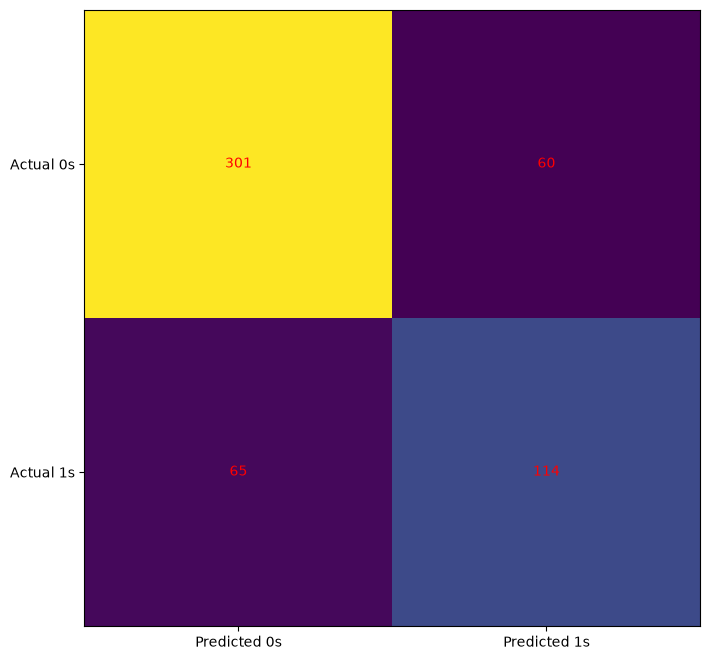

In [38]:
cm = confusion_matrix(y,clf.predict(x))

fig,ax = plt.subplots(figsize=(8,8))
ax.imshow(cm)
ax.grid(False)
ax.xaxis.set(ticks=(0, 1), ticklabels=('Predicted 0s', 'Predicted 1s'))
ax.yaxis.set(ticks=(0, 1), ticklabels=('Actual 0s', 'Actual 1s'))
ax.set_ylim(1.5, -0.5)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='red')
plt.show()

### Visual Representation of the Confusion Matrix

I converted the confusion matrix into a visual display using Matplotlib. The axis labels distinguish the actual classes from the predicted classes, and the numeric annotations make the number of observations in each cell easy to read.

This visualization makes the distribution of correct predictions and classification errors more accessible than a numerical array alone. It supports a more intuitive interpretation of how the classifier behaves across the two outcome classes.


In [39]:
print(classification_report(y,clf.predict(x)))

              precision    recall  f1-score   support

           0       0.82      0.83      0.83       361
           1       0.66      0.64      0.65       179

    accuracy                           0.77       540
   macro avg       0.74      0.74      0.74       540
weighted avg       0.77      0.77      0.77       540



### Evaluating Precision, Recall, and F1-Score

I generated a classification report to examine the model's performance separately for each target class. Precision measures how many predictions assigned to a class are correct, while recall measures how many actual observations belonging to that class are identified by the model. The F1-score combines precision and recall into a single measure, and support reports the number of actual observations in each class.

These metrics provide a more detailed evaluation than accuracy alone. In a medical classification context, examining recall for the diabetic class is especially informative because it indicates how many of the recorded diabetic cases the model successfully identifies. The report therefore helps describe the classifier's strengths and limitations across both classes.


In [40]:
p1 = clf.predict([[60,32,43,93,29.7,0.371,60]])
p1

c:\Users\11\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


array([0])

### Testing the Classifier on an Individual Observation

I passed a single set of feature values to the trained classifier to demonstrate how it can make a prediction for an individual observation. The values are supplied in the same feature order used when the model was trained, allowing the classifier to apply the patterns it learned from the training data.

The returned class represents the model's predicted category for this input. This example illustrates how a trained classifier can be used after fitting, beyond evaluating a batch of test observations. The prediction is a demonstration of the model's output, not a medical diagnosis.


In [41]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
k_fold = KFold(5)
print(cross_val_score(clf,x,y.ravel(),cv=k_fold,n_jobs=1))

[0.7962963  0.66666667 0.75       0.78703704 0.77777778]


### Assessing Performance Across Multiple Folds

I used `KFold` with five splits to evaluate the classifier across multiple partitions of the dataset. In each fold, a different portion of the data is held out for evaluation while the remaining observations are used to fit the model. `cross_val_score()` returns a score for each fold.

This approach provides a view of how the model's performance varies across different data partitions rather than relying on a single split. Comparing the five scores helps illustrate whether the classifier performs similarly across the folds or whether its results vary depending on which observations are used for evaluation.


In [42]:
table2 = table1[table1.index<108]
table3 = table1[table1.index>216]
table4 = pd.concat([table2, table3])
table4.reset_index(drop=True,inplace=True)
table4

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72,35,0,33.6,0.627,50,1
1,85,66,29,0,26.6,0.351,31,0
2,89,66,23,94,28.1,0.167,21,0
3,137,40,35,168,43.1,2.288,33,1
4,78,50,32,88,31.0,0.248,26,1
...,...,...,...,...,...,...,...,...
426,170,74,31,0,44.0,0.403,43,1
427,101,76,48,180,32.9,0.171,63,0
428,122,70,27,0,36.8,0.340,27,0
429,121,72,23,112,26.2,0.245,30,0


### Creating a Selected Subset for a Second Experiment

I created a new DataFrame by combining two selected portions of `table1`: rows with index values below 108 and rows with index values above 216. I then reset the index to give the combined subset a consecutive sequence of row labels.

This step establishes a different collection of observations for a second modeling experiment. By creating a separate DataFrame, I can define the data used in this experiment without overwriting the earlier filtered dataset. The resulting subset becomes the basis for the feature definition and model evaluation in the following cells.


In [44]:
x= pd.DataFrame(table4,columns=['Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age'])
y= table4.Outcome.values.reshape(-1,1)

### Preparing the Features and Target for the New Subset

I selected the same group of input features from `table4` and assigned the `Outcome` column to the target variable `y`. Keeping the feature structure consistent with the previous experiment makes it possible to apply the same classification approach to this new subset.

The feature matrix contains the measurements supplied to the classifier, while the target contains the class labels that the model is expected to predict. Separating these components prepares the subset for a new train-test split and model-fitting stage.


In [45]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.35,random_state=0)

### Creating Training and Testing Sets for the Second Experiment

I divided the selected subset into training and testing sets using `train_test_split()`, with 35% of the observations reserved for testing. The training data provide the examples used to fit the classifier, while the test data provide a separate set of observations for measuring its predictive performance.

Using `random_state=0` makes this split reproducible. Applying the same split configuration as in the earlier experiment also makes the workflow easier to follow, while the different underlying dataset allows me to examine the classifier's behavior on a different selection of observations.


In [46]:
clf = GaussianNB()
clf.fit(x_train,y_train.ravel())
y_pred = clf.predict(x_test)

### Training Gaussian Naive Bayes on the Selected Subset

I initialized a new `GaussianNB` classifier and fitted it using the training portion of the selected subset. During fitting, the model estimates the class-specific means and variances of the numerical features and uses these estimates to calculate class probabilities under its Gaussian assumptions.

I then used the fitted classifier to predict the target labels for `x_test`. These predictions are stored in `y_pred` and provide the basis for evaluating this second experiment. Repeating the same modeling procedure allows me to examine how the classifier performs when trained on a different collection of observations.


In [47]:
print("Accuracy:", metrics.accuracy_score(y_test,y_pred))

Accuracy: 0.8410596026490066


### Measuring Accuracy on the Second Test Set

I calculated the accuracy of the newly trained classifier by comparing its predictions with the actual labels in the second test set. The result summarizes the proportion of test observations classified correctly in this experiment.

The accuracy provides a direct measure for describing the model's performance on this selected subset. Comparing it with the earlier experiment helps illustrate that classification results can vary with the observations used to train and evaluate a model. The score should therefore be interpreted in the context of the dataset and test split used for this run.


In [48]:
confusion_matrix(y,clf.predict(x))

array([[255,  41],
       [ 46,  89]])

### Inspecting Predictions Across Both Classes

I generated a confusion matrix to summarize how the classifier's predicted labels compare with the actual labels in the selected dataset. The matrix shows the counts of correct and incorrect predictions for both the non-diabetic and diabetic classes.

This view helps describe the types of classification outcomes produced by the second model. Looking at the individual cells provides more information than accuracy alone because it distinguishes false positives from false negatives and shows how the predictions are distributed between the two classes.


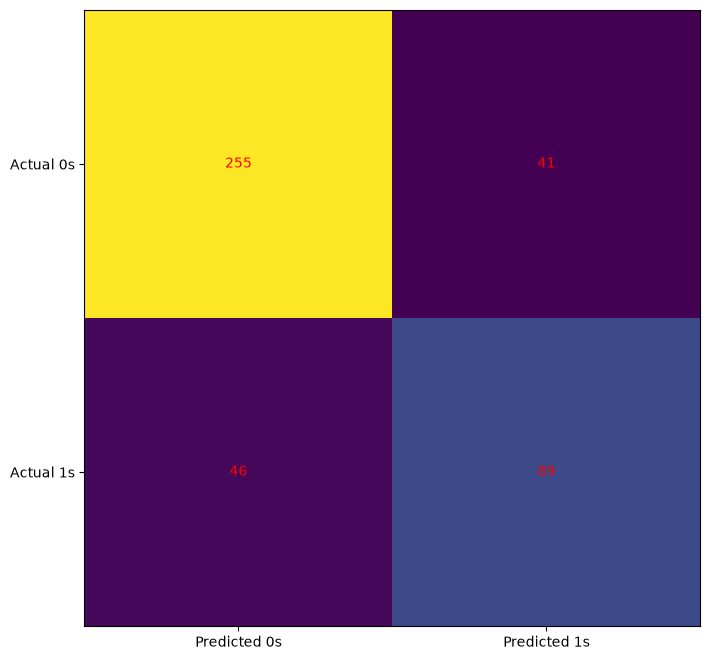

In [49]:
cm = confusion_matrix(y,clf.predict(x))

fig,ax = plt.subplots(figsize=(8,8))
ax.imshow(cm)
ax.grid(False)
ax.xaxis.set(ticks=(0, 1), ticklabels=('Predicted 0s', 'Predicted 1s'))
ax.yaxis.set(ticks=(0, 1), ticklabels=('Actual 0s', 'Actual 1s'))
ax.set_ylim(1.5, -0.5)
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='red')
plt.show()

### Visualizing the Classification Results

I displayed the confusion matrix as a plot and added labels for the actual and predicted classes. Each cell contains the corresponding number of observations, making it easier to interpret the distribution of predictions visually.

The plot provides a compact representation of how the classifier performs across the two target classes. It also makes the different error types easier to identify and supports the interpretation of the numerical evaluation results from the preceding cell.


In [50]:
p1 = clf.predict([[60,32,43,93,29.7,0.371,60]])
p1

c:\Users\11\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


array([0])

### Applying the Second Model to an Individual Example

I supplied one observation containing the selected patient features to the classifier trained in the second experiment. The model uses the feature values in the specified order to produce a predicted class.

This step demonstrates how the fitted model can be applied to an individual input after the training process. It connects the model-building stage to a simple prediction workflow, where feature values are provided and the classifier returns a category. As with the earlier example, the output is a model prediction for educational purposes and should not be interpreted as a clinical diagnosis.


In [51]:
print(classification_report(y,clf.predict(x)))

              precision    recall  f1-score   support

           0       0.85      0.86      0.85       296
           1       0.68      0.66      0.67       135

    accuracy                           0.80       431
   macro avg       0.77      0.76      0.76       431
weighted avg       0.80      0.80      0.80       431



### Detailed Evaluation of the Second Classifier

I generated a classification report to examine precision, recall, F1-score, and support for both classes in the selected dataset. These metrics describe different aspects of the classifier's performance: precision focuses on the correctness of positive predictions, recall measures how many actual cases of each class are identified, and the F1-score balances precision and recall.

The report provides a more complete description of the second experiment than accuracy alone. In particular, examining the metrics for the diabetic class helps explain how effectively the classifier identifies observations whose recorded outcome indicates diabetes. Considering these class-level results alongside the confusion matrix provides a broader understanding of the model's predictive behavior.


## Conclusion

In this project, I explored a diabetes dataset, examined selected numerical features through descriptive statistics and visualizations, prepared the data for classification, and implemented a Gaussian Naive Bayes model. I evaluated the classifier using accuracy, a confusion matrix, a classification report, and five-fold cross-validation to examine different aspects of its predictive performance.

I also conducted a second modeling experiment using a selected subset of the filtered dataset. This provided an opportunity to observe how the same classification algorithm behaves when the composition of the dataset changes.

Overall, this project helped me practice the main stages of a supervised machine learning workflow, from data exploration and feature preparation to model training, prediction, and evaluation. It also demonstrated the importance of examining class-level metrics alongside overall accuracy when evaluating a binary classifier.
